# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Mã nằm trong package `day10/` (chạy được cả trên Colab T4 lẫn máy thuê Vast.ai); notebook gọi lại từng bước.
Muốn chạy hết một lèo trên terminal: `SMOKE=1 bash run_all.sh` (thử ~10 phút) rồi `bash run_all.sh`.

| Bước | Module |
|---|---|
| nhãn, prompt | `day10/common.py` |
| encode + mask loss + collate | `day10/data.py` |
| nạp 4-bit, LoRA E1/E2/E3, projector | `day10/modeling.py` |
| huấn luyện / suy luận / chấm | `day10/train.py`, `day10/infer.py`, `day10/evidence.py` |
| GRPO + reward | `day10/grpo.py`, `day10/reward.py` (test: `day10/tests/`) |
| phân tích, ảnh | `day10/analyze.py`, `day10/coord_check.py` |

Mỗi lần huấn luyện/suy luận chạy trong **tiến trình con** (`!python -m ...`) → GPU được giải phóng sau mỗi bước, không phải restart runtime giữa E1/E2/E3.

## 0. Môi trường (Colab T4 hoặc Vast.ai)

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/tam253211-a11y/K4-Track-4-Day10-DangHuuTam-2A202602940-VisionLanguageModel.git"
if not os.path.exists("scripts/score.py"):               # chưa đứng trong repo → clone rồi cd vào
    REPO_DIR = os.path.join("/content" if IN_COLAB else os.getcwd(), REPO_URL.rsplit("/", 1)[-1][:-4])
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
    %cd {REPO_DIR}
os.environ["PYTHONPATH"] = os.getcwd()
os.environ["PYTHONIOENCODING"] = "utf-8"
sys.path.insert(0, os.getcwd())
!nvidia-smi -L
!pip -q install -r requirements-colab.txt pytest matplotlib datasets requests

GPU 0: NVIDIA GeForce RTX 5090 (UUID: GPU-db8604f2-c3f0-9147-bb06-8115f60213b0)


In [2]:
# Công cụ của đề: kỳ vọng 68 passed, 1 skipped (test dữ liệu thật skip khi chưa có data/)
!python -m pytest -q tests
# Test của mình (nhãn ↔ trọng tài, reward E5) — không cần GPU
!python -m pytest -q day10/tests

..........

................

.s.........................................    [100%]
68 passed, 1 skipped in 0.15s


......................                                                   [100%]
22 passed in 0.03s


In [3]:
# Sao lưu adapter (Colab free có thể bị ngắt). Trên Vast: để BACKUP_DIR = "" (đĩa máy thuê không mất giữa chừng)
BACKUP_DIR = ""
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_DIR = "/content/drive/MyDrive/day10_vlm"
    os.makedirs(BACKUP_DIR, exist_ok=True)
BK = f"--backup-dir {BACKUP_DIR}" if BACKUP_DIR else ""

In [4]:
# Kaggle: Colab → biểu tượng 🔑 → thêm KAGGLE_USERNAME, KAGGLE_KEY và BẬT "Notebook access".
# Vast: export KAGGLE_USERNAME=... KAGGLE_KEY=... trong terminal trước khi mở Jupyter. KHÔNG viết khoá vào notebook.
if IN_COLAB:
    from google.colab import userdata
    for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        try:
            os.environ[k] = userdata.get(k)
        except Exception as e:
            print(f"thiếu secret {k}: {type(e).__name__} — tạo secret và bật Notebook access, "
                  "hoặc dùng --zip ở cell dưới")
print({k: bool(os.environ.get(k)) for k in ("KAGGLE_USERNAME", "KAGGLE_KEY")})

{'KAGGLE_USERNAME': False, 'KAGGLE_KEY': False}


## 1. Dữ liệu: tải và chia split theo phiên quay

In [5]:
if not os.path.exists("data/splits/meta.json"):
    !python scripts/prepare_data.py --kaggle
    # Không có Kaggle key: tải zip tay, upload lên Drive rồi dùng:
    # !python scripts/prepare_data.py --zip "/content/drive/MyDrive/<file>.zip"

dataset_version: d10-21e4070301
train ảnh= 1422 pothole= 1074 crack= 1750 manhole=  691 ảnh_rỗng=   0 sessions= 13  OK
val   ảnh=  276 pothole=   66 crack=  470 manhole=  103 ảnh_rỗng=   0 sessions=  2  OK
test  ảnh=  311 pothole=  121 crack=  299 manhole=  163 ảnh_rỗng=   0 sessions=  3  OK
session trùng giữa các split: không có


[figure] /workspace/lab/report/figures/data_samples.png


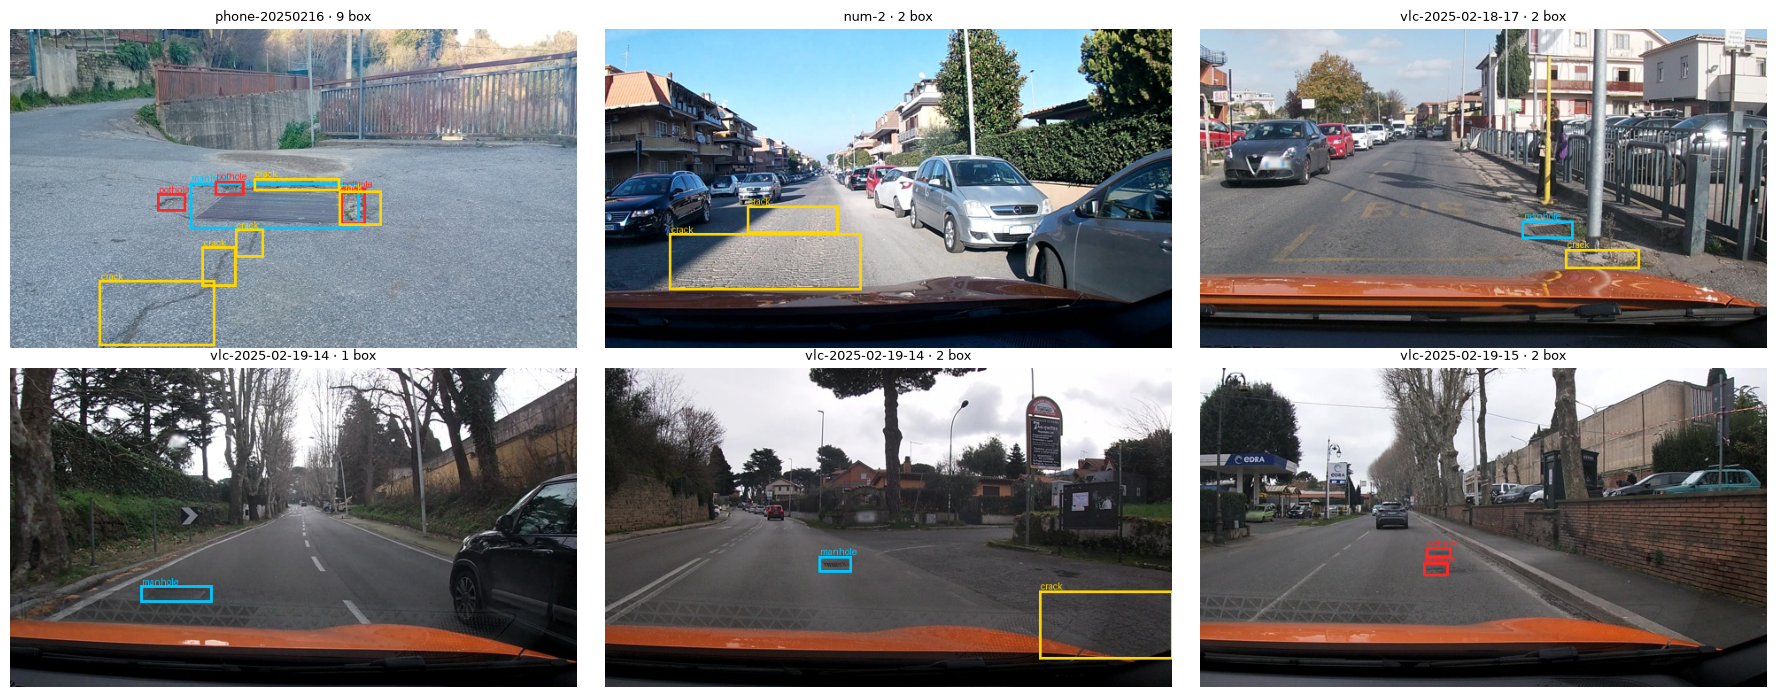

In [6]:
# Kiểm tra: dataset_version d10-…, số ảnh/box đúng bảng đề, không session nào ở hai split; vẽ 6 ảnh có box
%matplotlib inline
from day10.check_data import check, figure
splits, meta = check()
figure(splits);

## 2. Nhãn: YOLO → JSON thang 0–1000
`day10/common.py`: `yolo_to_box` (tâm+kích thước [0,1] → góc ×1000, làm tròn, kẹp [0,1000], không để box suy biến vì
`score.parse_output` coi `x2<=x1` là JSON hỏng) và `objects_to_answer` (sắp theo `(y1, x1)`, JSON không khoảng trắng).

In [7]:
import inspect, json
from day10 import common
print(inspect.getsource(common.yolo_to_box)); print(inspect.getsource(common.objects_to_answer))
print("PROMPT:", common.get_prompt("norm1000"))
rec = next(r for r in splits["train"] if len(r["objects"]) >= 3)
print("answer:", common.objects_to_answer(rec["objects"]))

def yolo_to_box(label, yolo, coord="norm1000", width=640, height=360):
    """YOLO (xc, yc, w, h chuẩn hoá [0,1]) → {"label", "bbox_2d": [x1,y1,x2,y2]} số nguyên."""
    xc, yc, w, h = yolo
    sx, sy = (1000, 1000) if coord == "norm1000" else (width, height)

    def clamp(v, hi):
        return int(round(max(0.0, min(float(hi), v))))

    x1, y1 = clamp((xc - w / 2) * sx, sx), clamp((yc - h / 2) * sy, sy)
    x2, y2 = clamp((xc + w / 2) * sx, sx), clamp((yc + h / 2) * sy, sy)
    # box suy biến (x2<=x1) bị score.parse_output coi là JSON hỏng → nới ra 1 đơn vị
    if x2 <= x1:
        x1, x2 = (x1, x1 + 1) if x1 < sx else (x1 - 1, x1)
    if y2 <= y1:
        y1, y2 = (y1, y1 + 1) if y1 < sy else (y1 - 1, y1)
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects, coord="norm1000", width=640, height=360):
    boxes = [yolo_to_box(o["label"], o["yolo"], coord, width, height) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0

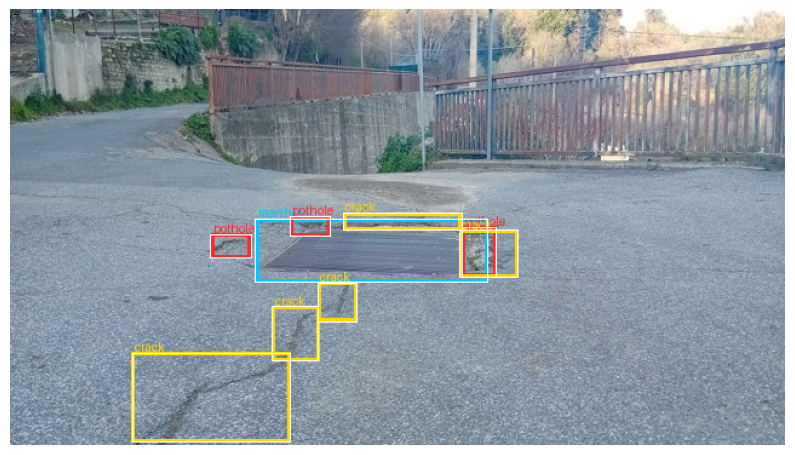

Oracle (nhãn đúng làm dự đoán) trên test:
  nhãn 0–1000, chấm --coord norm1000               valid=1.000 F1=1.000 (TP=583, FP=0, FN=0)
  nhãn pixel,  chấm --coord pixel                  valid=1.000 F1=1.000 (TP=583, FP=0, FN=0)
  nhãn pixel,  chấm --coord norm1000 (SAI THANG)   valid=1.000 F1=0.000 (TP=0, FP=583, FN=583)


  nhãn 0–1000, chấm --coord pixel    (SAI THANG)   valid=1.000 F1=0.000 (TP=0, FP=583, FN=583)


In [8]:
# Kiểm tra quy đổi ngược: box JSON 0–1000 → pixel, vẽ viền trắng chồng lên box gốc (màu) — phải trùng khít
import matplotlib.pyplot as plt
from PIL import ImageDraw
from day10.check_data import draw_gt
img = draw_gt(rec); d = ImageDraw.Draw(img); W, H = img.size
for b in json.loads(common.objects_to_answer(rec["objects"])):
    x1, y1, x2, y2 = b["bbox_2d"]
    d.rectangle([x1 * W / 1000, y1 * H / 1000, x2 * W / 1000, y2 * H / 1000], outline="white", width=1)
plt.figure(figsize=(10, 6)); plt.imshow(img); plt.axis("off"); plt.show()
# Câu 3: dùng chính trọng tài để thấy lệch thang làm F1 sụp dù JSON hợp lệ
!python -m day10.coord_check

## 3. E0: zero-shot

In [9]:
# Model gốc 4-bit NF4, llm_int8_skip_modules=["model.visual","lm_head"] (ViT + projector + lm_head giữ fp16; "visual" không khớp ở transformers 5.19). Batch 4, greedy.
# Gỡ lỗi trước trên 8 ảnh val, xem output thô:
!python -m day10.infer --zero-shot --split val --limit 8 --out work/debug/e0_val8.jsonl

[skip] work/debug/e0_val8.jsonl đã đủ 8 ảnh
--- vlcsnap-2025-02-18-18h30m17s408
[{"label": "crack", "bbox_2d": [10, 370, 550, 650]}]
--- vlcsnap-2025-02-18-18h30m20s293
[{"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 576, 100, 600]}, {"label": "crack", "bbox_2d": [10, 
--- vlcsnap-2025-02-18-18h30m22s081
[{"label": "crack", "bbox_2d": [0, 550, 1000, 650]}, {"label": "crack", "bbox_2d": [0, 550, 1000, 650]}]
--- vlcsnap-2025-02-18-18h30m24s122
[{"label": "crack", "bbox_2d": [0, 450, 1000, 750]}, {"label": "crack", "bbox_2d": [0, 450, 1000, 750]}, {"label": "manhole", "bbox_2d": [575, 476, 630, 500]}, {"label": "manhole", "bbox_2d": [885, 700, 998, 750]}]
--- vlcsnap-2025-02-18-18h30m25s530
[{

In [10]:
!python -m day10.infer --zero-shot --out work/e0.jsonl
!python -m day10.evidence --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
!python -m day10.analyze e0 --pred work/e0.jsonl

[skip] work/e0.jsonl đã đủ 311 ảnh
--- vlcsnap-00200
[{"label": "manhole", "bbox_2d": [770, 640, 843, 686]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 822]}]
--- vlcsnap-00201
[]
--- vlcsnap-00202
[{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]
--- vlcsnap-00203
[]
--- vlcsnap-00204
[{"label": "manhole", "bbox_2d": [257, 627, 325, 657]}]


$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json --split test --coord norm1000


E0 [test] n=311 valid=0.839 P=0.121 R=0.067 F1=0.086 CI95=0.061-0.113 meanIoU=0.602 FP/img=0.91
   pothole  P=0.286 R=0.066 F1=0.107
   crack    P=0.039 R=0.027 F1=0.032
   manhole  P=0.256 R=0.141 F1=0.182


n=311 · JSON hỏng=50 (16.1%) · bọc ```=0 · có chữ thừa=0
tổng box dự đoán=321 · GT=583 · nhãn dự đoán={'manhole': 90, 'crack': 203, 'pothole': 28}
toạ độ lớn nhất: median=710 (thang 0–1000; >1000 = sai thang)
box có toạ độ >1000: 0
--- JSON hỏng vlcsnap-2025-02-18-23h07m53s515: '[{"label": "crack", "bbox_2d": [500, 350, 520, 360]}, {"label": "crack", "bbox_2d": [520, 350, 540, 360]}, {"label": "crack", "bbox_2d": [540, 350, 560, 360]}, {"label": "crack", "bbox_2d": [560, 350, 580, 360]}, {"label": "crack", "bbox_2d": [580, 350, 600, 360]}, {"label": "crack", "bbox_2d": [600'
--- JSON hỏng vlcsnap-2025-02-18-23h08m10s837: '[{"label": "crack", "bbox_2d": [287, 478, 357, 500]}, {"label": "crack", "bbox_2d": [287, 478, 357, 500)}]'
--- JSON hỏng vlcsnap-2025-02-18-23h10m39s932: '[{"label": "crack", "bbox_2d": [12, 350, 100, 375]}, {"label": "crack", "bbox_2d": [12, 375, 100, 400]}, {"label": "crack", "bbox_2d": [12, 400, 100, 425]}, {"label": "crack", "bbox_2d": [12, 425, 100, 450]}, {"lab

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss
`day10/data.py::encode_example`: chuỗi prompt (ảnh + câu lệnh, `add_generation_prompt=True`) phải là tiền tố của chuỗi
đầy đủ; `labels[:n_prompt] = -100` → chỉ học JSON đáp án + `<|im_end|>`. `collate` pad `input_ids/attention_mask/`
`mm_token_type_ids/labels` (labels đệm -100) và **nối** `pixel_values/image_grid_thw` theo chiều 0.
> transformers 5.19 bắt buộc có `mm_token_type_ids` (M-RoPE) — collate mẫu trong đề thiếu khoá này sẽ báo ValueError.

In [11]:
import torch
from day10.data import GroundingDataset, make_collate, num_image_tokens
from day10.modeling import load_processor
processor = load_processor()
ds = GroundingDataset(splits["train"], processor)
ex = ds[0]
print("keys:", list(ex))
print("image_grid_thw:", ex["image_grid_thw"].tolist(), "→ token ảnh =", num_image_tokens(ex["image_grid_thw"]),
      "(Qwen3-VL patch 16, gộp 2×2: 640×360 → 640×352 → 40×22 patch → 20×11 = 220)")
n_learn = int((ex["labels"] != -100).sum()); n_all = ex["input_ids"].numel()
print(f"seq={n_all} token, học {n_learn} token ({n_learn / n_all:.1%}), mask {n_all - n_learn}")
print("labels != -100 giải mã:", repr(processor.tokenizer.decode(ex["input_ids"][ex["labels"] != -100])))
print("đáp án               :", repr(common.objects_to_answer(splits["train"][0]["objects"])))
batch = make_collate(processor.tokenizer.pad_token_id)([ds[0], ds[1]])
print({k: tuple(v.shape) for k, v in batch.items()})

keys: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'labels', 'pixel_values', 'image_grid_thw']
image_grid_thw: [[1, 22, 40]] → token ảnh = 220 (Qwen3-VL patch 16, gộp 2×2: 640×360 → 640×352 → 40×22 patch → 20×11 = 220)
seq=562 token, học 250 token (44.5%), mask 312
labels != -100 giải mã: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
đáp án               : '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"l

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [12]:
# day10/modeling.py::apply_setup — regex trên tên module thật (PEFT fullmatch), assert 252 (E1/E2) và 348 (E3).
# KHÔNG dùng list hậu tố ["qkv","linear_fc1","linear_fc2"]: sẽ khớp nhầm merger/deepstack (cũng có linear_fc1/2) và thiếu attn.proj.
from day10.modeling import LLM_RE, VIT_RE, architecture_breakdown
print("LLM:", LLM_RE); print("ViT:", VIT_RE)
arch = architecture_breakdown()      # đếm trên model 'meta' (không tải trọng số) — số cho Câu 1
for k, v in arch.items():
    print(f"{k:32s} {v:,}" if isinstance(v, int) and not isinstance(v, bool) else f"{k:32s} {v}")

LLM: model\.language_model\.layers\.\d+\.(?:self_attn\.(?:q|k|v|o)_proj|mlp\.(?:gate|up|down)_proj)
ViT: model\.visual\.blocks\.\d+\.(?:attn\.(?:qkv|proj)|mlp\.linear_fc[12])


vit_blocks+embed                 306,242,560
visual.merger                    27,271,680
visual.deepstack_merger_list     81,833,472
language_model                   4,022,468,096
lm_head(untied)                  0
total                            4,437,815,808
tie_word_embeddings              True
vision                           {'patch_size': 16, 'spatial_merge_size': 2, 'depth': 24, 'deepstack_visual_indexes': [5, 11, 17]}
text_layers                      36


## 6. Vòng huấn luyện
AdamW lr 2e-4 (wd 0), warmup 5% + cosine, GradScaler fp16, gradient checkpointing (use_reentrant=False), batch 2 × accum 4,
300 bước, clip 1.0. Lưu adapter **và** `projector.pt` (E2/E3) mỗi 100 bước; ghi `run.json` (trainable_params, peak_vram_gb,
train_minutes, loss). Hết VRAM: thêm `--batch-size 1 --grad-accum 8` (batch hiệu dụng vẫn 8, ghi chú trong báo cáo).

In [13]:
# Chạy thử 3 bước để bắt lỗi sớm (xem: 220 token ảnh, số module LoRA, VRAM)
!python -m day10.train --config configs/e1.yaml --out work/smoke_e1 --max-steps 3

[data] 1422 ảnh train, coord=norm1000


[check] image_grid_thw=[[1, 22, 40]] → 220 token ảnh; seq=562 token, học 250 token
[check] labels giải mã: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'


Loading weights:   0%|                                 | 0/713 [00:00<?, ?it/s]

Loading weights:   0%|                         | 1/713 [00:00<01:40,  7.05it/s]

Loading weights:   2%|▍                       | 14/713 [00:00<00:10, 68.32it/s]

...

[apply_setup] targets=llm projector=False r=16 alpha=32 → {'lora_modules': 252, 'lora_params': 33030144, 'projector_params': 0, 'trainable_params': 33030144}


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


step    1/3 loss=2.0736 lr=2.00e-04 gnorm=6.01 0.0ph (còn ~0.1ph) vram_peak=5.67GB


step    3/3 loss=0.8292 lr=0.00e+00 gnorm=0.38 0.1ph (còn ~0.0ph) vram_peak=5.94GB


[save] work/smoke_e1/adapter
[done] E1: trainable=33,030,144 peak_vram=5.94GB time=0.1ph loss 1.283 → 1.283


In [14]:
!python -m day10.train --config configs/e1.yaml --out work/e1 {BK}

[skip] work/e1/run.json đã có — bỏ qua (dùng --force để train lại)


In [15]:
!python -m day10.train --config configs/e2.yaml --out work/e2 {BK}

[skip] work/e2/run.json đã có — bỏ qua (dùng --force để train lại)


In [16]:
!python -m day10.train --config configs/e3.yaml --out work/e3 {BK}

[skip] work/e3/run.json đã có — bỏ qua (dùng --force để train lại)


## 7. Suy luận và chấm E1–E3
Nạp model gốc 4-bit → adapter → projector (`load_projector` in checksum trước/sau để chắc projector đã đổi).
`day10.evidence` lấy `--meta` **nguyên văn** từ `run.json` (không gõ tay số). Mẹo: gỡ lỗi với `--split val --limit 40`.

In [17]:
!python -m day10.infer --run work/e1 --split val --limit 40 --out work/debug/e1_val40.jsonl
!python -m day10.evidence --pred work/debug/e1_val40.jsonl --name E1val --split val --run work/e1 --out work/debug/e1_val40.json

[skip] work/debug/e1_val40.jsonl đã đủ 40 ảnh
--- vlcsnap-2025-02-18-18h30m17s408
[{"label":"crack","bbox_2d":[131,450,259,544]},{"label":"crack","bbox_2d":[388,461,541,550]},{"label":"crack","bbox_2d":[131,550,259,633]},{"label":"crack","bbox_2d":[388,553,541,639]},{"label":"crack","bbox_2d":[131,636,259,736]},{"label":"crack","bbox_2d":[388,639,541,736]}]
--- vlcsnap-2025-02-18-18h30m20s293
[{"label":"crack","bbox_2d":[11,489,509,761]}]
--- vlcsnap-2025-02-18-18h30m22s081
[{"label":"crack","bbox_2d":[2,483,250,761]},{"label":"crack","bbox_2d":[381,500,620,783]}]
--- vlcsnap-2025-02-18-18h30m24s122
[{"label":"crack","bbox_2d":[117,444,205,500]},{"label":"crack","bbox_2d":[250,450,331,508]},{"label":"crack","bbox_2d":[434,456,520,517]},{"label":"crack","bbox_2d":[448,522,531,600]},{"label":"crack","bbox_2d":[531,661,609,750]},{"label":"crack","bbox_2d":[250,667,331,750]},{"label":"crack","bbox_2d":[117,672,250,750]},{"label":"crack","bbox_2d":[448,678,509,750]},{"label":"manhole","bbox

$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/debug/e1_val40.jsonl --name E1val --out work/debug/e1_val40.json --split val --meta trainable_params=33030144 --meta peak_vram_gb=6.87 --meta train_minutes=5.8 --coord norm1000


E1val [val] n=276 valid=0.141 P=0.244 R=0.034 F1=0.060 CI95=0.036-0.088 meanIoU=0.703 FP/img=0.25
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.151 R=0.023 F1=0.041
   manhole  P=0.846 R=0.107 F1=0.190


In [18]:
for k in ("e1", "e2", "e3"):
    !python -m day10.infer --run work/{k} --out work/{k}.jsonl
    !python -m day10.evidence --pred work/{k}.jsonl --name {k.upper()} --run work/{k} --out report/evidence/{k}.json
!python -m day10.analyze table

[skip] work/e1.jsonl đã đủ 311 ảnh
--- vlcsnap-00200
[{"label":"manhole","bbox_2d":[759,636,850,706]},{"label":"manhole","bbox_2d":[905,772,998,836]}]
--- vlcsnap-00201
[{"label":"crack","bbox_2d":[484,550,550,608]},{"label":"crack","bbox_2d":[550,556,609,611]}]
--- vlcsnap-00202
[{"label":"manhole","bbox_2d":[300,672,398,728]}]
--- vlcsnap-00203
[{"label":"crack","bbox_2d":[220,533,331,608]},{"label":"crack","bbox_2d":[120,544,219,608]},{"label":"crack","bbox_2d":[12,550,119,608]}]
--- vlcsnap-00204
[{"label":"manhole","bbox_2d":[250,622,359,678]}]


$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e1.jsonl --name E1 --out report/evidence/e1.json --split test --meta trainable_params=33030144 --meta peak_vram_gb=6.87 --meta train_minutes=5.8 --coord norm1000


E1 [test] n=311 valid=0.984 P=0.264 R=0.249 F1=0.256 CI95=0.221-0.295 meanIoU=0.673 FP/img=1.30
   pothole  P=0.217 R=0.107 F1=0.144
   crack    P=0.162 R=0.217 F1=0.185
   manhole  P=0.761 R=0.411 F1=0.534


[skip] work/e2.jsonl đã đủ 311 ảnh
--- vlcsnap-00200
[{"label":"manhole","bbox_2d":[753,644,853,711]},{"label":"manhole","bbox_2d":[898,761,994,833]}]
--- vlcsnap-00201
[{"label":"crack","bbox_2d":[220,636,331,722]},{"label":"crack","bbox_2d":[481,683,536,806]}]
--- vlcsnap-00202
[{"label":"manhole","bbox_2d":[294,672,400,733]}]
--- vlcsnap-00203
[{"label":"crack","bbox_2d":[536,672,636,756]}]
--- vlcsnap-00204
[{"label":"manhole","bbox_2d":[250,622,348,672]}]


$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e2.jsonl --name E2 --out report/evidence/e2.json --split test --meta trainable_params=142135296 --meta peak_vram_gb=8.69 --meta train_minutes=5.9 --coord norm1000


E2 [test] n=311 valid=1.000 P=0.362 R=0.341 F1=0.351 CI95=0.312-0.393 meanIoU=0.682 FP/img=1.13
   pothole  P=0.202 R=0.182 F1=0.191
   crack    P=0.277 R=0.298 F1=0.287
   manhole  P=0.733 R=0.540 F1=0.622


[skip] work/e3.jsonl đã đủ 311 ảnh
--- vlcsnap-00200
[{"label":"crack","bbox_2d":[356,653,536,761]}]
--- vlcsnap-00201
[{"label":"crack","bbox_2d":[556,736,639,803]}]
--- vlcsnap-00202
[{"label":"manhole","bbox_2d":[291,661,398,728]},{"label":"pothole","bbox_2d":[419,672,453,706]}]
--- vlcsnap-00203
[{"label":"crack","bbox_2d":[494,678,648,756]},{"label":"crack","bbox_2d":[891,717,978,783]}]
--- vlcsnap-00204
[{"label":"manhole","bbox_2d":[253,622,339,667]}]


$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e3.jsonl --name E3 --out report/evidence/e3.json --split test --meta trainable_params=148426752 --meta peak_vram_gb=8.88 --meta train_minutes=7.3 --coord norm1000


E3 [test] n=311 valid=1.000 P=0.457 R=0.417 F1=0.436 CI95=0.394-0.480 meanIoU=0.698 FP/img=0.93
   pothole  P=0.314 R=0.314 F1=0.314
   crack    P=0.360 R=0.331 F1=0.345
   manhole  P=0.779 R=0.650 F1=0.709


| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | parse_valid |
|---|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 |  |  | 0.086 | 0.061–0.113 | 0.91 | 0.107 | 0.032 | 0.182 | 0.839 |
| E1 | LoRA LLM | 33,030,144 | 6.87 | 5.8 | 0.256 | 0.221–0.295 | 1.30 | 0.144 | 0.185 | 0.534 | 0.984 |
| E2 | + projector | 142,135,296 | 8.69 | 5.9 | 0.351 | 0.312–0.393 | 1.13 | 0.191 | 0.287 | 0.622 | 1.000 |
| E3 | + LoRA ViT | 148,426,752 | 8.88 | 7.3 | 0.436 | 0.394–0.480 | 0.93 | 0.314 | 0.345 | 0.709 | 1.000 |
| E4_data_0.1 | E4_data_0.1 | 148,426,752 | 8.28 | 11.5 | 0.289 | 0.252–0.327 | 1.62 | 0.220 | 0.211 | 0.547 | 0.997 |
| E4_data_1.0 | E4_data_1.0 | 148,426,752 | 8.88 | 7.3 | 0.436 | 0.394–0.480 | 0.93 | 0.314 | 0.345 | 0.709 | 1.000 |
| E5 | GRPO | 39,321,600 | 6.12 | 7.1 | 0.449 | 0.407–0.494 | 0.76 | 0.349 | 0.354 | 0.706 | 1.000 |


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)
**E4 = data_size** trên setup tốt nhất của E1–E3: chỉ đổi số ảnh train (10% vs 100%), giữ nguyên mọi thứ khác
(kể cả 300 bước → 10% dữ liệu lặp ~17 epoch). Giá trị 100% chính là setup gốc (GUIDE cho phép) → chỉ chấm lại.

In [19]:
f1 = {k: json.load(open(f"report/evidence/{k}.json"))["micro"]["f1"] for k in ("e1", "e2", "e3")}
BEST = max(f1, key=f1.get); print(f1, "→ setup gốc cho E4/E5:", BEST)
!python -m day10.evidence --pred work/{BEST}.jsonl --name E4_data_1.0 --run work/{BEST} --out report/evidence/e4_data_1.0.json
!python -m day10.train --config configs/{BEST}.yaml --out work/e4_data_0.1 --name E4_data_0.1 --train-fraction 0.1 {BK}
!python -m day10.infer --run work/e4_data_0.1 --out work/e4_data_0.1.jsonl
!python -m day10.evidence --pred work/e4_data_0.1.jsonl --name E4_data_0.1 --run work/e4_data_0.1 --out report/evidence/e4_data_0.1.json

{'e1': 0.25595763459841125, 'e2': 0.351279788172992, 'e3': 0.43587443946188337} → setup gốc cho E4/E5: e3
$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e3.jsonl --name E4_data_1.0 --out report/evidence/e4_data_1.0.json --split test --meta trainable_params=148426752 --meta peak_vram_gb=8.88 --meta train_minutes=7.3 --coord norm1000


E4_data_1.0 [test] n=311 valid=1.000 P=0.457 R=0.417 F1=0.436 CI95=0.394-0.480 meanIoU=0.698 FP/img=0.93
   pothole  P=0.314 R=0.314 F1=0.314
   crack    P=0.360 R=0.331 F1=0.345
   manhole  P=0.779 R=0.650 F1=0.709


[skip] work/e4_data_0.1/run.json đã có — bỏ qua (dùng --force để train lại)


[skip] work/e4_data_0.1.jsonl đã đủ 311 ảnh
--- vlcsnap-00200
[{"label":"crack","bbox_2d":[366,650,539,717]},{"label":"manhole","bbox_2d":[761,656,848,708]},{"label":"manhole","bbox_2d":[903,772,986,828]}]
--- vlcsnap-00201
[{"label":"crack","bbox_2d":[330,650,497,769]},{"label":"crack","bbox_2d":[523,667,652,806]},{"label":"pothole","bbox_2d":[805,736,877,814]}]
--- vlcsnap-00202
[{"label":"manhole","bbox_2d":[284,661,402,722]},{"label":"pothole","bbox_2d":[411,672,456,717]}]
--- vlcsnap-00203
[{"label":"crack","bbox_2d":[867,669,966,772]}]
--- vlcsnap-00204
[{"label":"manhole","bbox_2d":[252,619,338,667]}]


$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e4_data_0.1.jsonl --name E4_data_0.1 --out report/evidence/e4_data_0.1.json --split test --meta trainable_params=148426752 --meta peak_vram_gb=8.28 --meta train_minutes=11.5 --coord norm1000


E4_data_0.1 [test] n=311 valid=0.997 P=0.267 R=0.316 F1=0.289 CI95=0.252-0.327 meanIoU=0.668 FP/img=1.62
   pothole  P=0.203 R=0.240 F1=0.220
   crack    P=0.181 R=0.254 F1=0.211
   manhole  P=0.627 R=0.485 F1=0.547


In [20]:
# E5 (tuỳ chọn): test reward trước, rồi GRPO 60 bước từ adapter tốt nhất
!python -m pytest -q day10/tests/test_reward.py
!python -m day10.grpo --init work/{BEST} --out work/e5 {BK}
!python -m day10.infer --run work/e5 --out work/e5.jsonl
!python -m day10.evidence --pred work/e5.jsonl --name E5 --run work/e5 --out report/evidence/e5.json
!python -m day10.analyze hacking --pred work/{BEST}.jsonl work/e5.jsonl

.............                                                            [100%]
13 passed in 0.01s


[skip] work/e5/run.json đã có — bỏ qua (dùng --force để chạy lại)


[skip] work/e5.jsonl đã đủ 311 ảnh
--- vlcsnap-00200
[{"label":"crack","bbox_2d":[356,653,536,722]}]
--- vlcsnap-00201
[{"label":"crack","bbox_2d":[556,736,653,803]}]
--- vlcsnap-00202
[{"label":"manhole","bbox_2d":[289,661,398,722]}]
--- vlcsnap-00203
[{"label":"crack","bbox_2d":[494,678,653,753]}]
--- vlcsnap-00204
[{"label":"manhole","bbox_2d":[253,622,339,667]}]


$ /venv/main/bin/python /workspace/lab/scripts/score.py --pred work/e5.jsonl --name E5 --out report/evidence/e5.json --split test --meta trainable_params=39321600 --meta peak_vram_gb=6.12 --meta train_minutes=7.1 --coord norm1000


E5 [test] n=311 valid=1.000 P=0.502 R=0.407 F1=0.449 CI95=0.407-0.494 meanIoU=0.701 FP/img=0.76
   pothole  P=0.370 R=0.331 F1=0.349
   crack    P=0.399 R=0.318 F1=0.354
   manhole  P=0.810 R=0.626 F1=0.706


| file | parse_valid | tỷ lệ '[]' | ảnh GT rỗng | box/ảnh (pred) | box/ảnh (GT) | diện tích box TB | box >25% ảnh |
|---|---|---|---|---|---|---|---|
| work/e3.jsonl | 1.000 | 0.000 | 0.000 | 1.71 | 1.87 | 2.17% | 0 |
| work/e5.jsonl | 1.000 | 0.000 | 0.000 | 1.52 | 1.87 | 2.31% | 0 |


| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | parse_valid |
|---|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 |  |  | 0.086 | 0.061–0.113 | 0.91 | 0.107 | 0.032 | 0.182 | 0.839 |
| E1 | LoRA LLM | 33,030,144 | 6.87 | 5.8 | 0.256 | 0.221–0.295 | 1.30 | 0.144 | 0.185 | 0.534 | 0.984 |
| E2 | + projector | 142,135,296 | 8.69 | 5.9 | 0.351 | 0.312–0.393 | 1.13 | 0.191 | 0.287 | 0.622 | 1.000 |
| E3 | + LoRA ViT | 148,426,752 | 8.88 | 7.3 | 0.436 | 0.394–0.480 | 0.93 | 0.314 | 0.345 | 0.709 | 1.000 |
| E4_data_0.1 | E4_data_0.1 | 148,426,752 | 8.28 | 11.5 | 0.289 | 0.252–0.327 | 1.62 | 0.220 | 0.211 | 0.547 | 0.997 |
| E4_data_1.0 | E4_data_1.0 | 148,426,752 | 8.88 | 7.3 | 0.436 | 0.394–0.480 | 0.93 | 0.314 | 0.345 | 0.709 | 1.000 |
| E5 | GRPO | 39,321,600 | 6.12 | 7.1 | 0.449 | 0.407–0.494 | 0.76 | 0.349 | 0.354 | 0.706 | 1.000 |


Thống kê nhãn (diện tích box tính theo % khung hình):
  train pothole  n= 1074  median=0.38%  p25=0.19%  p75=0.75%
  train crack    n= 1750  median=1.35%  p25=0.60%  p75=3.15%
  train manhole  n=  691  median=0.39%  p25=0.23%  p75=0.64%
  val   pothole  n=   66  median=0.36%  p25=0.22%  p75=0.74%
  val   crack    n=  470  median=1.32%  p25=0.69%  p75=2.50%
  val   manhole  n=  103  median=0.66%  p25=0.41%  p75=1.04%
  test  pothole  n=  121  median=0.42%  p25=0.22%  p75=0.93%
  test  crack    n=  299  median=1.98%  p25=1.06%  p75=3.53%
  test  manhole  n=  163  median=0.67%  p25=0.40%  p75=1.12%



Recall theo lớp × kích thước (work/e3.jsonl, IoU≥0.5):
  pothole  <0.3%: 8/40=0.20 · 0.3–1%: 18/54=0.33 · ≥1%: 12/27=0.44
  crack    <0.3%: 0/7=0.00 · 0.3–1%: 6/61=0.10 · ≥1%: 93/231=0.40
  manhole  <0.3%: 9/21=0.43 · 0.3–1%: 60/95=0.63 · ≥1%: 37/47=0.79

Phân loại FP:
  crack→lệch vị trí (0<IoU<0.5): 121
  pothole→lệch vị trí (0<IoU<0.5): 43
  crack→bịa (IoU=0): 40
  pothole→nhầm lớp manhole: 17
  pothole→bịa (IoU=0): 15
  manhole→bịa (IoU=0): 13
  manhole→lệch vị trí (0<IoU<0.5): 13
  crack→nhầm lớp pothole: 10
  pothole→nhầm lớp crack: 8
  crack→nhầm lớp manhole: 5
  manhole→nhầm lớp pothole: 3
  manhole→nhầm lớp crack: 1


[figures] /workspace/lab/report/figures/e3_examples.png
![E3 · vlcsnap-2025-02-18-23h13m52s540 · TP=2 FP=0 FN=0](report/figures/e3_dung_1.png)
![E3 · vlcsnap-2025-02-18-23h13m55s630 · TP=2 FP=0 FN=0](report/figures/e3_dung_2.png)
![E3 · vlcsnap-2025-02-18-23h14m04s766 · TP=2 FP=0 FN=0](report/figures/e3_dung_3.png)
![E3 · vlcsnap-2025-02-18-23h30m33s636 · TP=0 FP=6 FN=1](report/figures/e3_sai_4.png)
![E3 · vlcsnap-2025-02-18-23h30m28s990 · TP=0 FP=4 FN=7](report/figures/e3_sai_5.png)
![E3 · vlcsnap-2025-02-18-23h16m49s457 · TP=0 FP=5 FN=3](report/figures/e3_sai_6.png)


Oracle (nhãn đúng làm dự đoán) trên test:
  nhãn 0–1000, chấm --coord norm1000               valid=1.000 F1=1.000 (TP=583, FP=0, FN=0)
  nhãn pixel,  chấm --coord pixel                  valid=1.000 F1=1.000 (TP=583, FP=0, FN=0)
  nhãn pixel,  chấm --coord norm1000 (SAI THANG)   valid=1.000 F1=0.000 (TP=0, FP=583, FN=583)
  nhãn 0–1000, chấm --coord pixel    (SAI THANG)   valid=1.000 F1=0.000 (TP=0, FP=583, FN=583)
Dự đoán thật work/e3.jsonl:
  chấm --coord norm1000 (đúng)                     valid=1.000 F1=0.436 (TP=243, FP=289, FN=340)
  chấm --coord pixel    (SAI THANG)                valid=1.000 F1=0.000 (TP=0, FP=532, FN=583)


/bin/bash: -c: line 1: syntax error near unexpected token `)'
/bin/bash: -c: line 1: `mkdir -p report/runs && for d in work/e*/; do [ -f <PIL.ImageDraw.ImageDraw object at 0x78a80ed42060>/run.json ] && cp <PIL.ImageDraw.ImageDraw object at 0x78a80ed42060>/run.json report/runs/$(basename <PIL.ImageDraw.ImageDraw object at 0x78a80ed42060>).json; done; cp work/*.info.json report/runs/ 2>/dev/null; true'


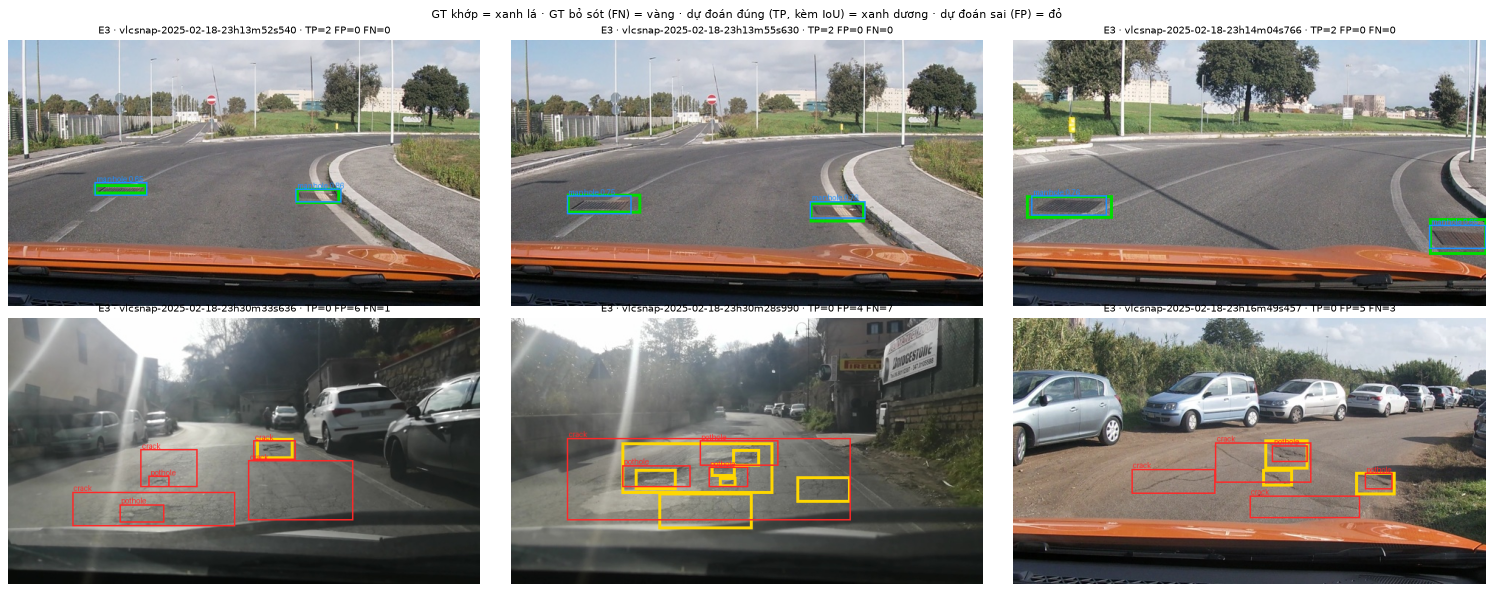

In [21]:
# Phân tích cho REPORT.md: bảng, lỗi theo lớp/kích thước (Câu 9), ảnh minh hoạ (≥6, box dự đoán + box đúng)
!python -m day10.analyze table
!python -m day10.analyze classes --pred work/{BEST}.jsonl
!python -m day10.analyze figures --pred work/{BEST}.jsonl --tag {BEST}
!python -m day10.coord_check --pred work/{BEST}.jsonl
!mkdir -p report/runs && for d in work/e*/; do [ -f $d/run.json ] && cp $d/run.json report/runs/$(basename $d).json; done; cp work/*.info.json report/runs/ 2>/dev/null; true
from IPython.display import Image as IPImage, display
display(IPImage(f"report/figures/{BEST}_examples.png"))

In [22]:
# Kiểm tra trước khi nộp (cần data/splits/meta.json để mục 'khớp meta.json' PASS)
!python scripts/check_submission.py

[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[FAIL] git commits — 0/5
[PASS] git forbidden files

2 FAIL, 0 WARN
